status: optimal
optimal worst-case objective t*: 1.1687609396729404

Worst-case vertex (a,b) (1-indexed): (1, 10)
Worst-case achieved value: 1.1689117475455624


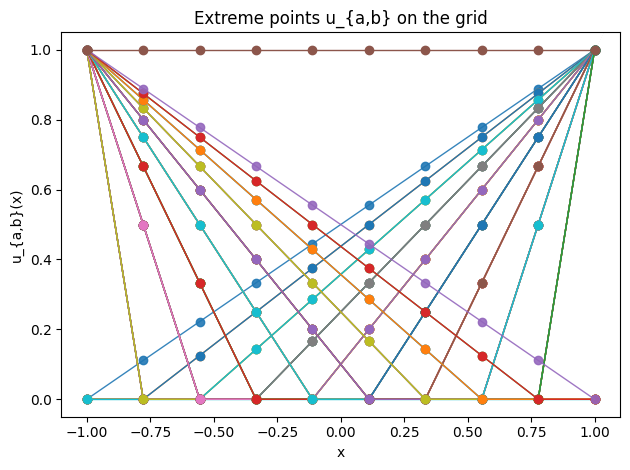

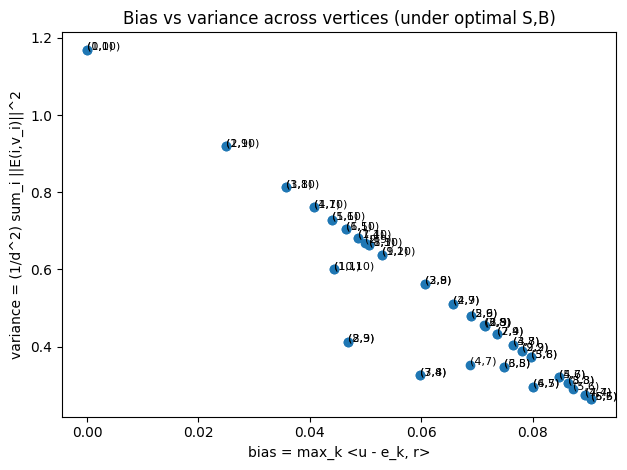

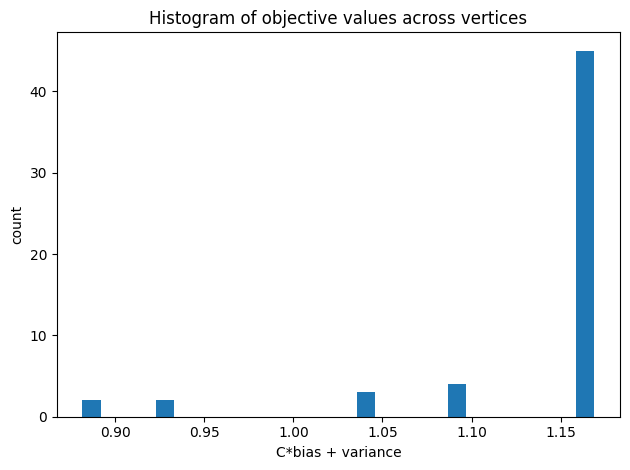

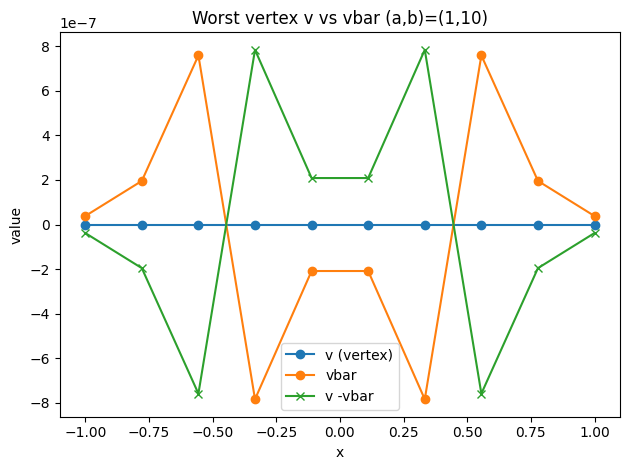

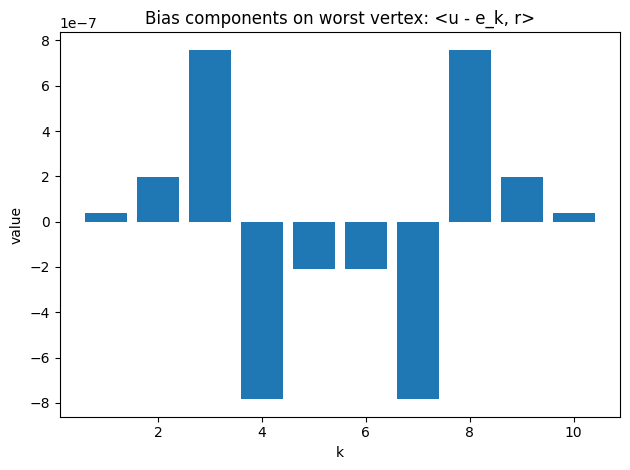

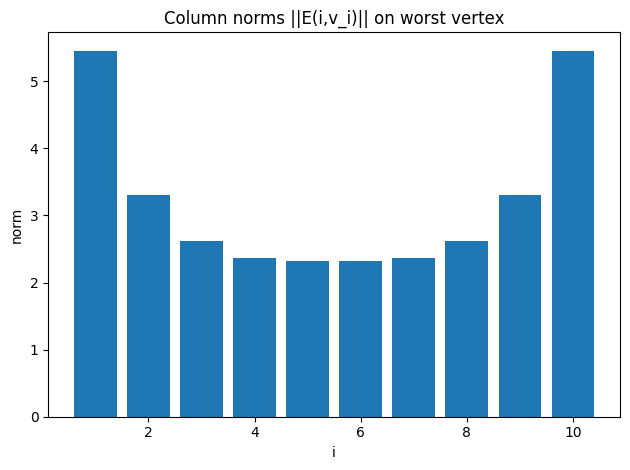

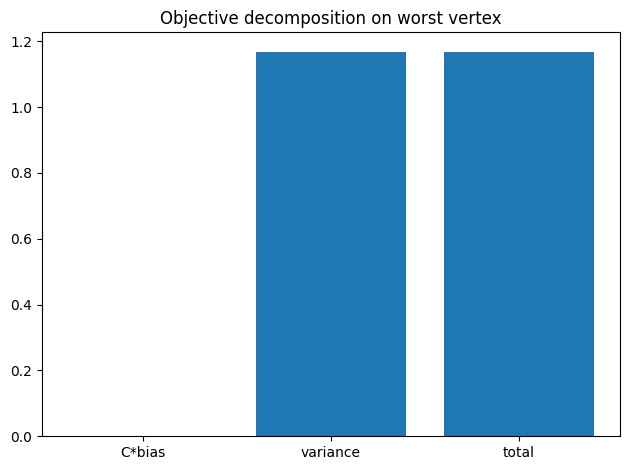

In [37]:
# Requires: pip install cvxpy numpy matplotlib
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

def make_grid(d: int, include_endpoints: bool = False) -> np.ndarray:
    """
    Grid on [-1,1].
    - include_endpoints=False: d interior points, avoids division-by-zero in u_{a,b}.
    - include_endpoints=True: includes -1 and 1, can create degeneracies in u_{a,b}.
    """
    if include_endpoints:
        return np.linspace(-1.0, 1.0, d)
    return np.linspace(-1.0, 1.0, d + 2)[1:-1]

def u_ab(x: np.ndarray, a: int, b: int) -> np.ndarray:
    """
    Extreme point u_{a,b} evaluated on grid x.
    a,b are 0-indexed with 0 <= a <= b <= d-1.

    Piecewise definition (in terms of x_i):
      for i <= a:      1 - (x_i+1)/(x_a+1)
      for a < i < b:   0
      for i >= b:      (x_i - x_b)/(1 - x_b)

    Includes safe handling when x_a=-1 or x_b=1 (degenerate chords).
    """
    d = len(x)
    xa, xb = x[a], x[b]
    v = np.zeros(d)

    eps = 1e-12
    for i in range(d):
        if i <= a:
            denom = xa + 1.0
            if abs(denom) < eps:
                # Degenerate: chord from (-1,1) to (-1,0); only defines value 0 at x=-1
                v[i] = 0.0
            else:
                v[i] = 1.0 - (x[i] + 1.0) / denom
        elif i < b:
            v[i] = 0.0
        else:
            denom = 1.0 - xb
            if abs(denom) < eps:
                # Degenerate: chord from (1,0) to (1,1); only defines value 0 at x=1
                v[i] = 0.0
            else:
                v[i] = (x[i] - xb) / denom

    return np.clip(v, 0.0, 1.0)

def extreme_points(d: int, include_endpoints: bool = False):
    x = make_grid(d, include_endpoints=include_endpoints)
    verts = []
    for a in range(d):
        for b in range(a, d):
            verts.append((a, b, u_ab(x, a, b)))
    
    # there is a total of d(d+1)/2 extreme points of the above form
    # there is also the all-one vector if endpoints are included
    if include_endpoints:
        verts.append(( -1, -1, np.ones(d)))  # special case for all-one vector
    return x, verts

def solve_minmax(d: int = 4,
                 C: float = 1.0,
                 include_endpoints: bool = False,
                 impose_zero_mean_columns: bool = True,
                 solver: str = "SCS",
                 verbose: bool = False):
    """
    Convex QCQP:
      minimize_{S,B}  max_{(a,b)} [ C * max_k <u-e_k, r(v)> + (1/d^2) sum_i || v_i s_i + b_i ||^2 ]
    where r(v) = (I - S/d) v - (1/d) sum_j b_j.

    Returns a dict with S,B and metadata.
    """
    x, verts = extreme_points(d, include_endpoints=include_endpoints)

    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d

    S = cp.Variable((d, d))  # columns s_i
    B = cp.Variable((d, d))  # columns b_i
    t = cp.Variable()        # epigraph

    bar_b = (1.0 / d) * (B @ ones)

    constraints = [t >= 0]

    if impose_zero_mean_columns:
        constraints += [
            ones @ S == np.zeros(d),  # 1^T s_i = 0 for each column
            ones @ B == np.zeros(d),  # 1^T b_i = 0 for each column
        ]

    for (a, b, v) in verts:
        theta = cp.Variable()

        r = (I - (1.0 / d) * S) @ v - bar_b

        for k in range(d):
            w = u.copy()
            w[k] -= 1.0
            constraints += [theta >= w @ r]

        var = 0
        for i in range(d):
            var += cp.sum_squares(v[i] * S[:, i] + B[:, i])
        var = var / (d ** 2)

        constraints += [t >= C * theta + var]

    prob = cp.Problem(cp.Minimize(t), constraints)
    prob.solve(solver=solver, verbose=verbose)

    return {
        "status": prob.status,
        "opt_value": prob.value,
        "S": S.value,
        "B": B.value,
        "x": x,
        "verts": verts,
        "C": C,
        "include_endpoints": include_endpoints,
        "zero_mean_cols": impose_zero_mean_columns,
        "solver": solver,
    }

def evaluate_solution(sol):
    S = sol["S"]
    B = sol["B"]
    C = sol["C"]
    verts = sol["verts"]

    d = S.shape[0]
    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d

    bar_b = (B @ ones) / d

    rows = []
    worst_val = -1e300
    worst = None

    for (a, b, v) in verts:
        vbar = (S @ v) / d + bar_b
        r = v - vbar
        bias_components = np.array([(u - np.eye(d)[k]) @ r for k in range(d)])
        bias = bias_components.max()

        E_mat = S @ np.diag(v) + B
        var = np.sum(np.linalg.norm(E_mat, axis=0) ** 2) / (d ** 2)

        val = C * bias + var
        rows.append({
            "a": a, "b": b,
            "bias": bias,
            "var": var,
            "obj": val,
            "v": v,
            "vbar": vbar,
            "r": r,
            "bias_components": bias_components,
            "E_mat": E_mat,
        })
        if val > worst_val:
            worst_val = val
            worst = rows[-1]

    return {
        "rows": rows,
        "worst": worst,
        "worst_value": worst_val,
        "worst_a_b_1indexed": (worst["a"] + 1, worst["b"] + 1),
    }

def plot_heatmap(A, title, xlabel="column", ylabel="row"):
    plt.figure()
    plt.imshow(A, aspect="auto")
    plt.colorbar()
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()

def plot_vertices(x, stats):
    """
    Plots all u_{a,b} as curves vs x. If worst_ab given (0-indexed tuple),
    highlight it by thicker line.
    """
    plt.figure()
    for stat in stats["rows"]:
        a = stat["a"]
        b = stat["b"]
        v = stat["v"]
        plt.plot(x, v, marker="o", linewidth=1, alpha=stat["obj"] / stats["worst_value"])
    plt.title("Extreme points u_{a,b} on the grid")
    plt.xlabel("x")
    plt.ylabel("u_{a,b}(x)")
    plt.tight_layout()

def plot_bias_variance_scatter(stats):
    rows = stats["rows"]
    biases = np.array([r["bias"] for r in rows])
    vars_ = np.array([r["var"] for r in rows])
    objs = np.array([r["obj"] for r in rows])

    plt.figure()
    plt.scatter(biases, vars_)
    for i, r in enumerate(rows):
        plt.annotate(f"({r['a']+1},{r['b']+1})", (biases[i], vars_[i]), fontsize=8)

    plt.title("Bias vs variance across vertices (under optimal S,B)")
    plt.xlabel("bias = max_k <u - e_k, r>")
    plt.ylabel("variance = (1/d^2) sum_i ||E(i,v_i)||^2")
    plt.tight_layout()

    plt.figure()
    plt.hist(objs, bins=max(5, len(objs)//2))
    plt.title("Histogram of objective values across vertices")
    plt.xlabel("C*bias + variance")
    plt.ylabel("count")
    plt.tight_layout()

def plot_worst_case_details(x, worst, C):
    v = worst["v"]
    vbar = worst["vbar"]
    r = worst["r"]
    bias_components = worst["bias_components"]
    E_mat = worst["E_mat"]

    a, b = worst["a"], worst["b"]
    d = len(v)

    plt.figure()
    plt.plot(x, v, marker="o", label="v (vertex)")
    plt.plot(x, vbar, marker="o", label="vbar")
    plt.plot(x, v - vbar, marker="x", label="v -vbar")
    plt.title(f"Worst vertex v vs vbar (a,b)=({a+1},{b+1})")
    plt.xlabel("x")
    plt.ylabel("value")
    plt.legend()
    plt.tight_layout()

    plt.figure()
    plt.bar(np.arange(1, d+1), bias_components)
    plt.title("Bias components on worst vertex: <u - e_k, r>")
    plt.xlabel("k")
    plt.ylabel("value")
    plt.tight_layout()

    # Column norms of E(i,v_i)
    col_norms = np.linalg.norm(E_mat, axis=0)
    plt.figure()
    plt.bar(np.arange(1, d+1), col_norms)
    plt.title("Column norms ||E(i,v_i)|| on worst vertex")
    plt.xlabel("i")
    plt.ylabel("norm")
    plt.tight_layout()

    # Decompose objective terms
    bias = worst["bias"]
    var = worst["var"]
    plt.figure()
    plt.bar(["C*bias", "variance", "total"], [C*bias, var, C*bias + var])
    plt.title("Objective decomposition on worst vertex")
    plt.tight_layout()

def visualize_solution(sol, stats, save_prefix=None, show=True, heatmaps=True):
    S = sol["S"]
    B = sol["B"]
    x = sol["x"]
    verts = sol["verts"]
    C = sol["C"]

    worst = stats["worst"]
    worst_ab = (worst["a"], worst["b"])

    if heatmaps:
        plot_heatmap(S, "Heatmap of S (columns are s(i))", xlabel="i (column)", ylabel="coordinate")
        plot_heatmap(B, "Heatmap of B (columns are b(i))", xlabel="i (column)", ylabel="coordinate")

    plot_vertices(x, stats)
    plot_bias_variance_scatter(stats)
    plot_worst_case_details(x, worst, C)

    if save_prefix is not None:
        for i, fig_num in enumerate(plt.get_fignums(), start=1):
            fig = plt.figure(fig_num)
            fig.savefig(f"{save_prefix}_{i:02d}.png", dpi=200, bbox_inches="tight")

    if show:
        plt.show()

if __name__ == "__main__":
    d = 10
    C = float(d)

    sol = solve_minmax(
        d=d,
        C=C,
        include_endpoints=True,          # safer numerically
        impose_zero_mean_columns=False,    # WLOG; reduces variance waste
        solver="SCS",
        verbose=False
    )

    print("status:", sol["status"])
    print("optimal worst-case objective t*:", sol["opt_value"])
    # print("\nS* =\n", sol["S"])
    # print("\nB* =\n", sol["B"])

    stats = evaluate_solution(sol)
    print("\nWorst-case vertex (a,b) (1-indexed):", stats["worst_a_b_1indexed"])
    print("Worst-case achieved value:", stats["worst_value"])
    visualize_solution(sol, stats, save_prefix=None, show=True, heatmaps=False)


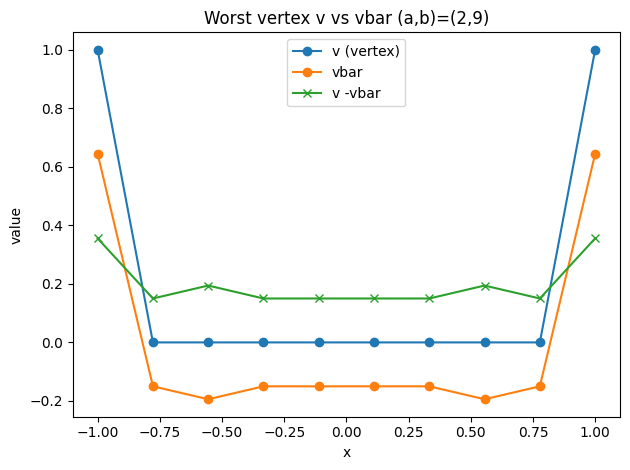

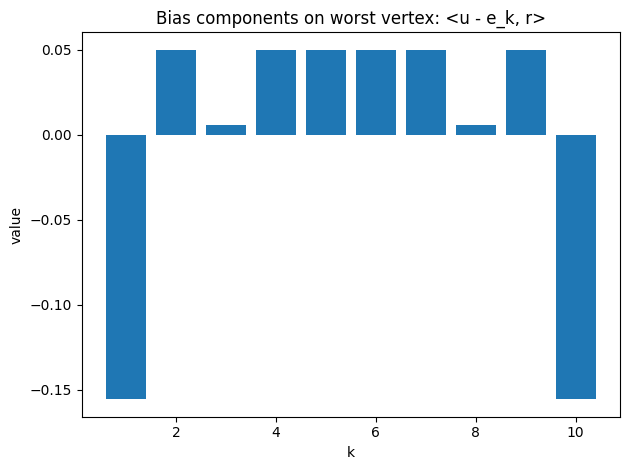

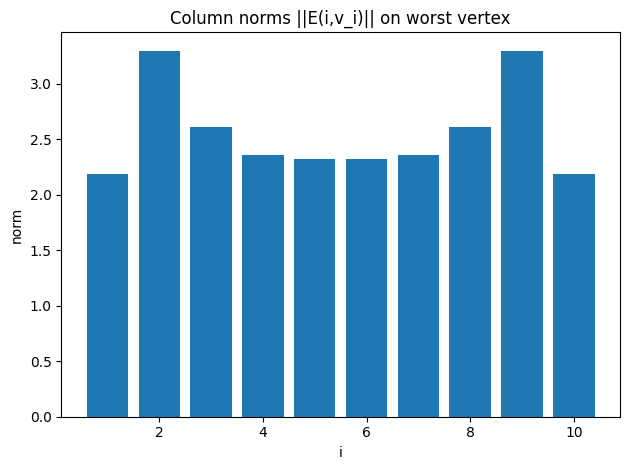

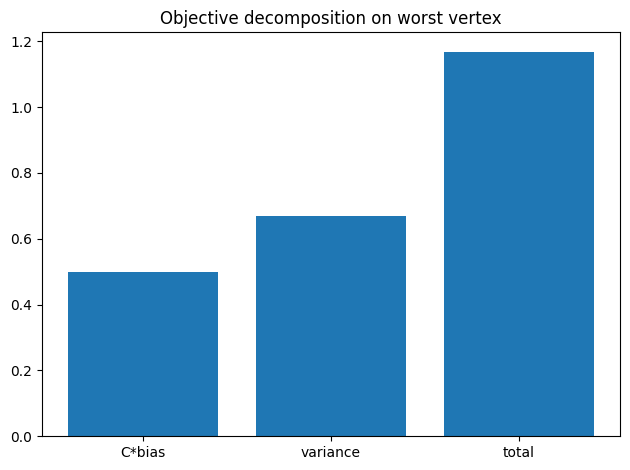

In [41]:
plot_worst_case_details(sol["x"], stats["rows"][17], C)

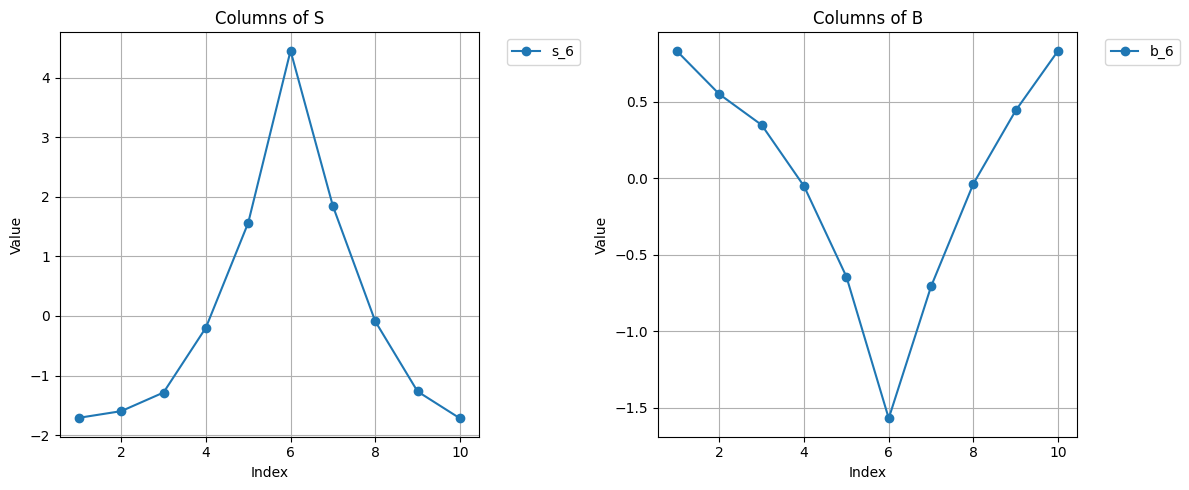

In [49]:
# plot each column of S and B as a function of index
def plot_S_B_columns(sol, indexes=range(d)):
    S = sol["S"]
    B = sol["B"]
    d = S.shape[0]
    indices = np.arange(1, d + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    for i in indexes:
        plt.plot(indices, S[:, i], marker='o', label=f's_{i+1}')
    plt.title('Columns of S')
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()

    plt.subplot(1, 2, 2)
    for i in indexes:
        plt.plot(indices, B[:, i], marker='o', label=f'b_{i+1}')
    plt.title('Columns of B')
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()

    plt.tight_layout()
    plt.show()
plot_S_B_columns(sol, indexes=[5])

d=1, C=1.0, t*=6.923527139299002e-06
d=2, C=2.0, t*=0.06249772538035559
d=3, C=3.0, t*=0.15031124338431576
d=4, C=4.0, t*=0.2244443233601096
d=5, C=5.0, t*=0.298260184638501
d=6, C=6.0, t*=0.3680969779311235
d=7, C=7.0, t*=0.43186712886757145
d=8, C=8.0, t*=0.4916302540624846
d=9, C=9.0, t*=0.547340937486077
d=10, C=10.0, t*=0.599273712601518
d=11, C=11.0, t*=0.6478440397924145
d=12, C=12.0, t*=0.6937682052399412
d=13, C=13.0, t*=0.737134511542159
d=14, C=14.0, t*=0.7783550291694019
d=15, C=15.0, t*=0.8177876282744629
d=16, C=16.0, t*=0.8554818556065052
d=17, C=17.0, t*=0.8914081984962255
d=18, C=18.0, t*=0.9259815679421263
d=19, C=19.0, t*=0.9594954363942381
d=20, C=20.0, t*=0.9920293853901516


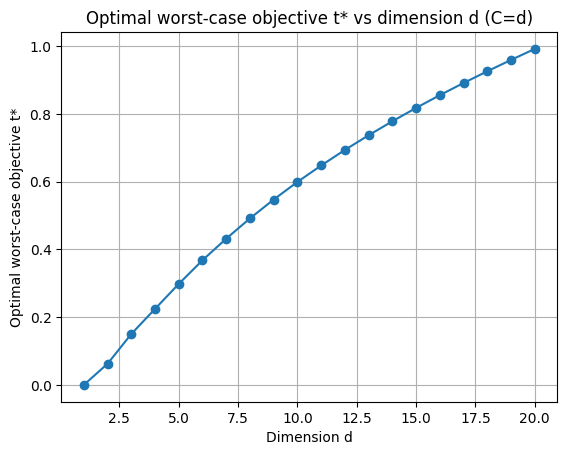

In [4]:
# check how t* grows with d for C = d

l = []
for dprime in range(20):
    d = (dprime+1)
    Cprime = float(d)
    sol_d = solve_minmax(
        d=d,
        C=Cprime,
        include_endpoints=False,
        impose_zero_mean_columns=True,
        solver="SCS",
        verbose=False
    )
    print(f"d={d}, C={Cprime}, t*={sol_d['opt_value']}")
    l.append((d, sol_d['opt_value']))

plt.figure()
ds = [item[0] for item in l]
ts = [item[1] for item in l]
plt.plot(ds, ts, marker='o')
plt.title("Optimal worst-case objective t* vs dimension d (C=d)")
plt.xlabel("Dimension d")
plt.ylabel("Optimal worst-case objective t*")
plt.grid()

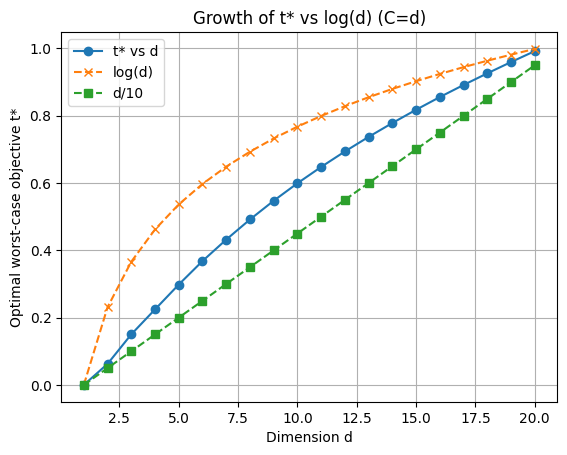

In [9]:
# check see if t* grows linearly with d or logarithmically with d
plt.figure()
plt.plot(ds, ts, marker='o', label='t* vs d')
plt.plot(ds, [np.log(d)/3 for d in ds], marker='x', label='log(d)', linestyle='--')
plt.plot(ds, [(d-1)/20 for d in ds], marker='s', label='d/10', linestyle='--')
plt.title("Growth of t* vs log(d) (C=d)")
plt.xlabel("Dimension d")
plt.ylabel("Optimal worst-case objective t*")
plt.legend()
plt.grid()

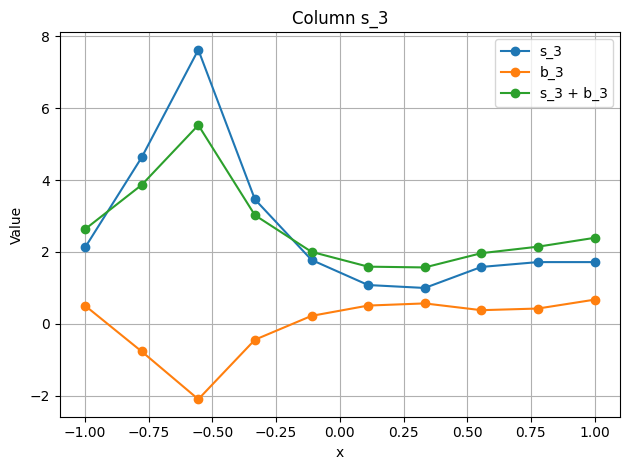

In [63]:
# Some experiments on S

i =2
s = sol['S'][:,i]
b = sol['B'][:,i]
# s += -np.min(s) + 1
# plt.plot(sol['x'], np.log(s), marker='o')
plt.plot(sol['x'], s, marker='o', label=f's_{i+1}')
plt.plot(sol['x'], b, marker='o', label=f'b_{i+1}')
plt.plot(sol['x'], s + b, marker='o', label=f's_{i+1} + b_{i+1}')
plt.title(f"Column s_{i+1}")
plt.xlabel("x")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()